# Fourier Transform - Spatial Frequencies 2

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-03.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        print("ipympl installed. Colab will restart the runtime once; when it has, run this cell again.")
        get_ipython().kernel.do_shutdown(restart=True)
    from google.colab import output
    output.enable_custom_widget_manager()

## Import libraries

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

In [6]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Define parameters

In [7]:
# --- 1. DATA GENERATION ---
wavelength = 2.0
theta = 0
range_val = 10.0
dx = range_val / 255.5

# Create Grid
x_vals = np.arange(-range_val, range_val, dx)
y_vals = np.arange(-range_val, range_val, dx)
X, Y = np.meshgrid(x_vals, y_vals)

# Generate 2D Sine Wave: sin(k*y)
data_1d = np.sin((2.0 * np.pi / wavelength) * x_vals)
data = np.sin((2.0 * np.pi / wavelength) * (np.cos(theta) * X + np.sin(theta) * Y))

# Compute Fourier Transform
ft = np.fft.fft2(data)
ft_shifted = np.fft.fftshift(ft)
ft_mag = np.abs(ft_shifted)
# Apply visual blur so the dots are visible
ft_visual = gaussian_filter(ft_mag, sigma=2)

## Plot

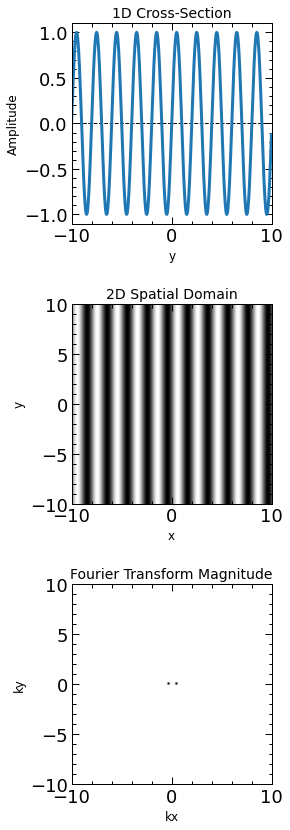

In [8]:
# --- 2. PLOT SETUP ---
# 3 Rows, 1 Column. Increased height to accommodate stacking.
fig1, (ax11, ax12, ax13) = plt.subplots(3, 1, figsize=(8, 14))
plt.subplots_adjust(hspace=0.4) # Add space between plots
# fig1.suptitle("Sinusoid Analysis: 1D, 2D, and Fourier", fontsize=18)

# --- HELPER: APPLY YOUR CUSTOM STYLE ---
def apply_custom_style(ax, title, xlabel, ylabel, is_image=False):
    ax.set_title(title, fontsize=14)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    
    # Tick formatting
    ax.minorticks_on()
    ax.tick_params(which='both', direction="in", width=1)
    ax.tick_params(which='major', length=7)
    ax.tick_params(which='minor', length=3.5)
    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')
    
    # Only add the dashed zero line for 1D plots
    if not is_image:
        ax.axhline(0, color='black', linewidth=1, linestyle='--', zorder=0)

# --- PLOT 1: 1D SLICE ---
ax11.plot(y_vals, data_1d, linewidth=3, color='tab:blue')
ax11.set_xlim(-range_val, range_val)
ax11.set_ylim(-1.1, 1.1)
ax11.set_box_aspect(1)
apply_custom_style(ax11, "1D Cross-Section", "y", "Amplitude")

# --- PLOT 2: 2D SPATIAL DOMAIN ---
# Note: origin='lower' puts (-10) at bottom, (10) at top
ax12.imshow(data, cmap='gray', origin='lower', 
           extent=[-range_val, range_val, -range_val, range_val], aspect='equal')
apply_custom_style(ax12, "2D Spatial Domain", "x", "y", is_image=True)

# --- PLOT 3: FOURIER TRANSFORM ---
# Using 'gray_r' to make peaks black on white
# Vmax trick ensures the background stays white even if there is noise
ax13.imshow(ft_visual, cmap='gray_r', origin='lower', 
           extent=[-range_val, range_val, -range_val, range_val], aspect='equal',
           vmax=np.max(ft_visual)*0.8) 
apply_custom_style(ax13, "Fourier Transform Magnitude", "kx", "ky", is_image=True)

plt.show()

### Save plot

In [ ]:
# fig1.savefig("../figures/ch05/ch05-03-FTspatialfrequencies-still.jpg", dpi=300, bbox_inches='tight')

## Add Sliders

In [ ]:
%matplotlib widget 

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider
from scipy.ndimage import gaussian_filter

# --- 1. CONFIGURATION ---
range_val = 10.0
resolution = 256  
dx = (2 * range_val) / resolution

lam_step = 0.1
ang_step = np.pi / 32 

# --- 2. SETUP DATA ARRAYS ---
x_vals = np.linspace(-range_val, range_val, resolution)
y_vals = np.linspace(-range_val, range_val, resolution)
X, Y = np.meshgrid(x_vals, y_vals)

# --- 3. CACHING SYSTEM ---
calc_cache = {}

def get_data(lam, ang):
    key = (round(lam, 2), round(ang, 2))
    if key in calc_cache:
        return calc_cache[key]
    
    k = 2.0 * np.pi / (lam + 1e-9)
    spatial = np.sin(k * (np.cos(ang) * X + np.sin(ang) * Y))
    
    ft = np.fft.fft2(spatial)
    ft_shifted = np.fft.fftshift(ft)
    ft_mag = np.abs(ft_shifted)
    fourier = gaussian_filter(ft_mag, sigma=1.5) 
    
    calc_cache[key] = (spatial, fourier)
    return spatial, fourier

# Initial Calculation
init_lam = 2.0
init_ang = 0.0
data_spatial, data_fourier = get_data(init_lam, init_ang)

# --- 4. PLOT SETUP ---
# 1 Row, 2 Columns. Wider figure.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
plt.subplots_adjust(bottom=0.25, wspace=0.3) # Extra space at bottom for sliders
fig.suptitle("Interactive Sinusoid Analysis", fontsize=16)
fig.canvas.header_visible = False
fig.canvas.footer_visible = False

# --- STYLE HELPER ---
def apply_style(ax, title, xlabel, ylabel):
    ax.set_box_aspect(1)  # Force Square
    ax.set_title(title, fontsize=12)
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.minorticks_on()
    ax.tick_params(which='both', direction="in", width=1)
    ax.tick_params(which='major', length=7)
    ax.tick_params(which='minor', length=3.5)
    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')

# Plot 1: Spatial
im1 = ax1.imshow(data_spatial, cmap='gray', origin='lower', 
                 extent=[-range_val, range_val, -range_val, range_val])
apply_style(ax1, "2D Spatial Domain", "x", "y")

# Plot 2: Fourier
im2 = ax2.imshow(data_fourier, cmap='gray_r', origin='lower',
                 extent=[-range_val, range_val, -range_val, range_val],
                 vmax=np.max(data_fourier)*0.8)
apply_style(ax2, "Fourier Transform Magnitude", "kx", "ky")

# --- 5. SLIDERS ---
# Position: [left, bottom, width, height]
# Centered nicely below the two plots
ax_lam = plt.axes([0.25, 0.1, 0.5, 0.03])
ax_ang = plt.axes([0.25, 0.05, 0.5, 0.03])

slider_lam = Slider(ax=ax_lam, label='Wavelength ', valmin=0.5, valmax=8.0, 
                    valinit=init_lam, valstep=lam_step)
slider_ang = Slider(ax=ax_ang, label='Theta (rad) ', valmin=0.0, valmax=2*np.pi, 
                    valinit=init_ang, valstep=ang_step)

# --- 6. UPDATE FUNCTION ---
def update(val):
    lam = slider_lam.val
    ang = slider_ang.val
    
    new_spatial, new_fourier = get_data(lam, ang)
    
    im1.set_data(new_spatial)
    im2.set_data(new_fourier)
    im2.set_clim(vmax=np.max(new_fourier)*0.8)
    
    fig.canvas.draw_idle()

slider_lam.on_changed(update)
slider_ang.on_changed(update)

plt.show()

### Save animation as mp4 file

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider
from scipy.ndimage import gaussian_filter
import matplotlib.animation as animation

# --- 1. CONFIGURATION ---
range_val = 10.0
resolution = 256  
dx = (2 * range_val) / resolution

# --- 2. SETUP DATA ARRAYS ---
x_vals = np.linspace(-range_val, range_val, resolution)
y_vals = np.linspace(-range_val, range_val, resolution)
X, Y = np.meshgrid(x_vals, y_vals)

# --- 3. CACHING SYSTEM & LOGIC ---
calc_cache = {}

def get_data(lam, ang):
    # Rounding helps cache hit rate
    key = (round(lam, 2), round(ang, 2))
    if key in calc_cache:
        return calc_cache[key]
    
    k = 2.0 * np.pi / (lam + 1e-9)
    spatial = np.sin(k * (np.cos(ang) * X + np.sin(ang) * Y))
    
    ft = np.fft.fft2(spatial)
    ft_shifted = np.fft.fftshift(ft)
    ft_mag = np.abs(ft_shifted)
    fourier = gaussian_filter(ft_mag, sigma=1.5) 
    
    calc_cache[key] = (spatial, fourier)
    return spatial, fourier

# Initial Calculation
init_lam = 2.0
init_ang = 0.0
data_spatial, data_fourier = get_data(init_lam, init_ang)

# --- 4. PLOT SETUP ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
plt.subplots_adjust(bottom=0.25, wspace=0.3)
fig.suptitle("Interactive Sinusoid Analysis", fontsize=16)

# --- STYLE HELPER ---
def apply_style(ax, title, xlabel, ylabel):
    ax.set_box_aspect(1)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')

# Plot 1: Spatial
im1 = ax1.imshow(data_spatial, cmap='gray', origin='lower', 
                 extent=[-range_val, range_val, -range_val, range_val])
apply_style(ax1, "2D Spatial Domain", "x", "y")

# Plot 2: Fourier
im2 = ax2.imshow(data_fourier, cmap='gray_r', origin='lower',
                 extent=[-range_val, range_val, -range_val, range_val],
                 vmax=np.max(data_fourier)*0.8)
apply_style(ax2, "Fourier Transform Magnitude", "kx", "ky")

# --- 5. SLIDERS ---
ax_lam = plt.axes([0.25, 0.1, 0.5, 0.03])
ax_ang = plt.axes([0.25, 0.05, 0.5, 0.03])

slider_lam = Slider(ax=ax_lam, label='Wavelength ', valmin=0.5, valmax=8.0, valinit=init_lam)
slider_ang = Slider(ax=ax_ang, label='Theta (rad) ', valmin=0.0, valmax=2*np.pi, valinit=init_ang)

# --- 6. ANIMATION CONFIGURATION ---

# A. Generate the list of frames
# We create a list of tuples: (wavelength, angle)
frames = []

# Phase 1: Fix Wavelength, Rotate Angle (0 to 2pi)
phase1_steps = 60
for ang in np.linspace(0, 2*np.pi, phase1_steps):
    frames.append((init_lam, ang))

# Phase 2: Fix Angle, Change Wavelength (0.5 to 8.0)
# We reset angle to 0 (which is visually the same as 2pi) for the sweep
phase2_steps = 60
for lam in np.linspace(0.5, 8.0, phase2_steps):
    frames.append((lam, 0.0))

print(f"Total Frames to render: {len(frames)}")

# B. Define the Animation Update Function
def animate(frame_data):
    lam, ang = frame_data
    
    # Update Data
    new_spatial, new_fourier = get_data(lam, ang)
    
    # Update Images
    im1.set_data(new_spatial)
    im2.set_data(new_fourier)
    im2.set_clim(vmax=np.max(new_fourier)*0.8)
    
    # Update Sliders (Visually only, to show progress in video)
    # We use .eventson = False to prevent the slider from triggering 
    # a recursive loop or double calculation
    slider_lam.eventson = False
    slider_ang.eventson = False
    slider_lam.set_val(lam)
    slider_ang.set_val(ang)
    slider_lam.eventson = True
    slider_ang.eventson = True
    
    return im1, im2, slider_lam, slider_ang

# --- 7. SAVE ANIMATION ---
print("Generating animation... this may take a moment.")

anim = animation.FuncAnimation(
    fig, 
    animate, 
    frames=frames, 
    interval=50, # 50ms per frame = 20 fps
    blit=False   # Blit False is safer for slider updates in video
)

# Use FFMpegWriter
writer = animation.FFMpegWriter(fps=24, metadata=dict(artist='Me'), bitrate=1800)
# Uncomment the two lines below to re-export the animation (needs ffmpeg installed):
# anim.save("../../animations/ch05/ch05-03.mp4", writer=writer)
# print("Done! Saved to '../../animations/ch05/ch05-03.mp4'")

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch05/ch05-03_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-03.html) (direct link: [ch05-03_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch05/ch05-03_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.